# VIS4AI · Notebook 02 — Plot results (without the support of AI)

Goal of this notebook: load the results from Notebook 01 and visualize the experiment results using matplotlib and seaborn. On Colab, results are read from Google Drive; locally, they are read from the repository's `data/<run>` folder. This notebook has been written without the help of agents/llms.

In [86]:
import ast
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
import re
import numpy as np
from pathlib import Path

RUN = "run_4_2026-11-08_15-40"

try:                               # on Colab: read from Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/VIS4AI/results") / RUN
except ImportError:                # locally: read from data/ in the repo
    data_dir = Path.cwd().parent / "data" if Path.cwd().name == "notebooks" else Path.cwd() / "data"
    RESULTS_DIR = next(p for p in [data_dir / RUN, data_dir / RUN.split("_2")[0]] if p.exists())
print("Reading results from:", RESULTS_DIR)

# Load the data from the results folder
result_folder = RESULTS_DIR

results_files = [f for f in os.listdir(result_folder) if f.endswith('.jsonl')]
parameters_files = [f for f in os.listdir(result_folder) if f.endswith('.txt')]

dfs = []
for file in results_files:
    data_path = os.path.join(result_folder, file)
    df = pd.read_json(data_path, lines=True)
    dfs.append(df)
    
# Concatenate all dataframes into a single dataframe
combined_df = pd.concat(dfs, ignore_index=True)

# Load parameters from text files
parameters = []
for file in parameters_files:
    param_path = os.path.join(result_folder, file)
    data_dict = {}
    with open(param_path, "r") as file:
        for line in file:
            # Strip whitespace/newlines and split by the delimiter
            if ":" in line:
                key, value = line.strip().split(":", 1)
                data_dict[key.strip()] = value.strip()
    
    print(data_dict)
    parameters.append(data_dict)
    
models = ast.literal_eval(parameters[0]['models'])
max_tokens = {cfg['name']: cfg['max_new_tokens'] for cfg in models.values()}
    
# New features
combined_df['words_in'] = combined_df['question'].apply(lambda x: len(x.split()))
combined_df['words_out'] = combined_df['output'].apply(lambda x: len(x.split()))
combined_df['numbers_out'] = combined_df['output'].apply(lambda x: len(re.findall(r'\d+', x)))
combined_df['model_short'] = combined_df["model"].str.split("/").str[-1]
combined_df['max_tokens'] = combined_df['model'].map(max_tokens)
combined_df['temperature'] = float(parameters[0]['temperature'])
combined_df['top_p'] = float(parameters[0]['top_p'])
combined_df['batch_size'] = int(parameters[0]['batch_size'])

combined_df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'run': 'run_4_2026-11-08_15-40', 'written': '2026-11-08 15:40:16', 'models': "{'r1-distill': {'name': 'deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B', 'thinks': True, 'chat_template': True, 'sampling': True, 'max_new_tokens': 8192, 'stop_after_answer': False}, 'qwen-math': {'name': 'Qwen/Qwen2.5-Math-1.5B', 'thinks': False, 'chat_template': False, 'sampling': False, 'max_new_tokens': 2048, 'stop_after_answer': True}}", 'n_problems': '50', 'batch_size': '12', 'temperature': '0.6', 'top_p': '0.95', 'seed': '42', 'instruction': 'Please reason step by step, and put your final answer within \\boxed{}.', 'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'transformers': '5.22.1'}


,id,question,gold,model,output,answer,correct,n_tokens,finished,batch_time,answer_time,chain_of_thought_length,words_in,words_out,numbers_out,model_short,max_tokens,temperature,top_p,batch_size
0,0,Janet’s ducks lay 16 eggs per day. She eats th...,18,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Okay, so I have this problem here about Janet ...",18,True,955,True,1394.442855,50.537230,36,52,684,73,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
1,1,A robe takes 2 bolts of blue fiber and half th...,3,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Alright, so I have this problem here: A robe t...",3,True,1238,True,1394.442855,68.532460,25,22,921,61,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
2,2,Josh decides to try flipping a house. He buys...,70000,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Okay, so Josh is buying a house for $80,000, a...",70000,True,2480,True,1394.442855,181.253761,37,35,1182,317,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
3,3,James decides to run 3 sprints 3 times a week....,540,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Alright, so James is trying to figure out how ...",180,False,960,True,1394.442855,50.840519,15,25,612,82,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
4,4,"Every day, Wendi feeds each of her chickens th...",20,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,"Alright, let me try to figure out how much fee...",None,False,8192,False,1394.442855,1394.139143,197,87,5795,659,DeepSeek-R1-Distill-Qwen-1.5B,8192,0.6,0.95,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,45,Meredith is a freelance blogger who writes abo...,104,Qwen/Qwen2.5-Math-1.5B,"To solve this problem, we need to follow these...",104,True,355,True,131.318299,16.244898,9,79,225,34,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
96,46,Candice put 80 post-it notes in her purse befo...,163,Qwen/Qwen2.5-Math-1.5B,"To solve this problem, we need to determine ho...",163,True,214,True,131.318299,9.437772,6,70,147,16,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
97,47,John buys twice as many red ties as blue ties....,800,Qwen/Qwen2.5-Math-1.5B,"To solve this problem, we need to follow these...",800,True,569,True,131.318299,25.749320,13,36,332,42,Qwen2.5-Math-1.5B,2048,0.6,0.95,12
98,48,Tracy used a piece of wire 4 feet long to supp...,8,Qwen/Qwen2.5-Math-1.5B,To determine how many pieces of wire Tracy obt...,8,True,194,True,14.936439,8.350592,4,31,115,13,Qwen2.5-Math-1.5B,2048,0.6,0.95,12


## Group by model

In [87]:

df_grouped = combined_df.groupby("model_short").agg(
                                    accuracy=("correct", "mean"),
                                    cut_off=("finished", lambda s: 1 - s.mean()),
                                    no_answer=("answer", lambda s: s.isna().mean()),
                                    mean_tokens=("n_tokens", "mean"),
                                    mean_chain_of_tought_length=("chain_of_thought_length", "mean"),
                                    mean_words_out=('words_out', 'mean'),
                                    mean_answer_time=('answer_time', 'mean'),
                                    mean_numbers_out=('numbers_out', 'mean'),
                                    max_tokens=('max_tokens', 'mean'),
                                    top_p=('top_p', 'mean'),
                                    temperature=('temperature', 'mean'),
                                    batch_size=('batch_size', 'mean')
                                    ).reset_index()

rates = df_grouped.melt(id_vars="model_short", value_vars=["accuracy", "cut_off", "no_answer"],
                        var_name="metric", value_name="rate")

df_grouped

,model_short,accuracy,cut_off,no_answer,mean_tokens,mean_chain_of_tought_length,mean_words_out,mean_answer_time,mean_numbers_out,max_tokens,top_p,temperature,batch_size
0,DeepSeek-R1-Distill-Qwen-1.5B,0.86,0.06,0.06,2344.60,59.26,1477.98,241.399821,238.74,8192.0,0.95,0.6,12.0
1,Qwen2.5-Math-1.5B,0.80,0.04,0.04,420.86,6.84,259.80,20.785271,33.60,2048.0,0.95,0.6,12.0


## Plotting functions

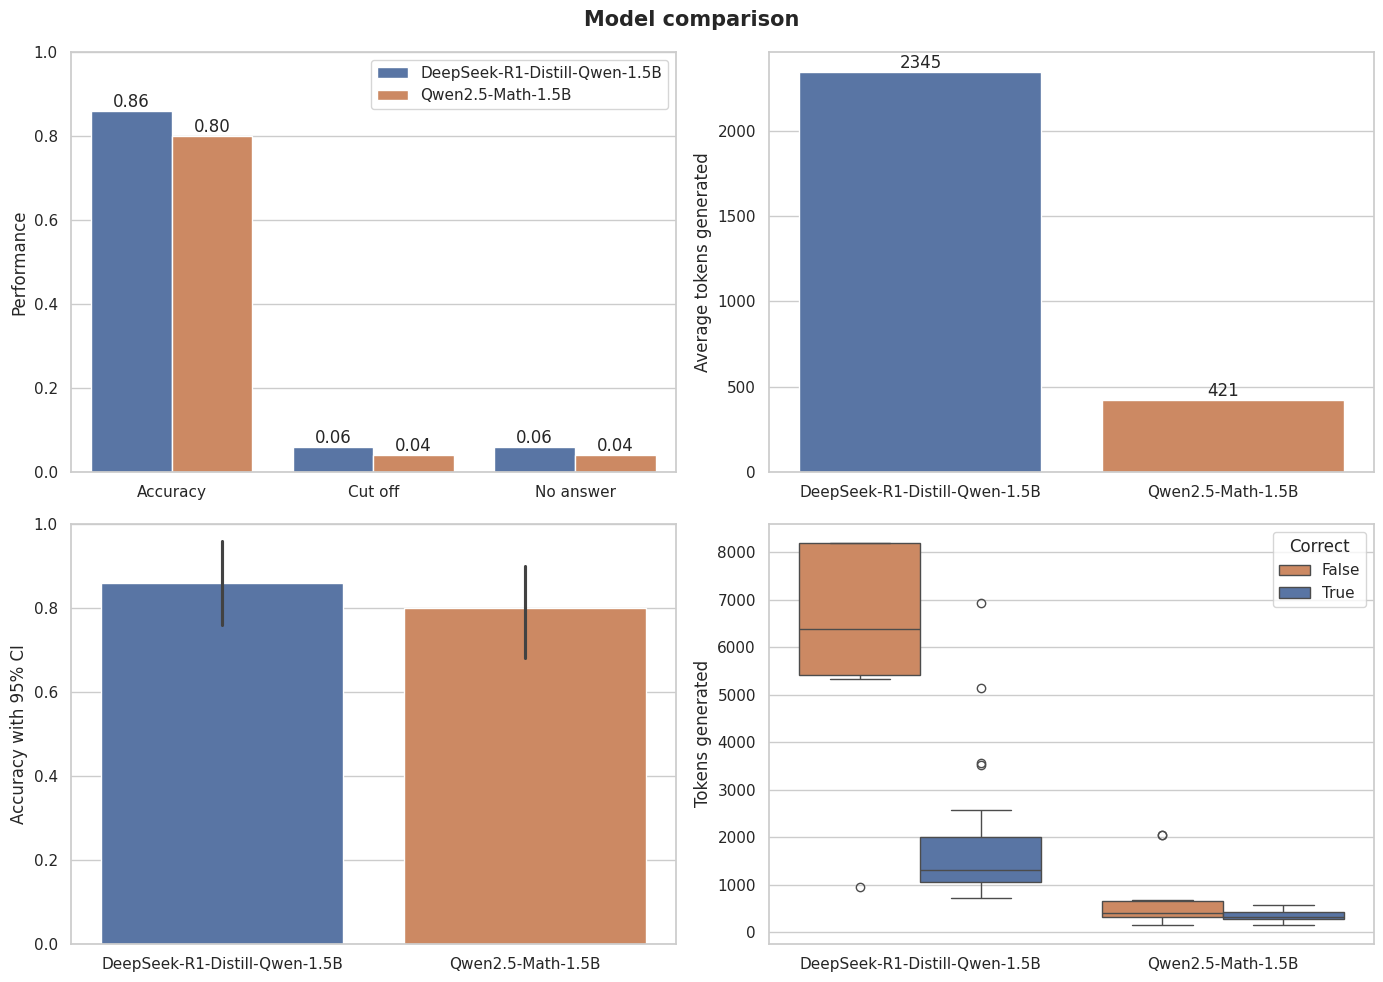

In [88]:
sns.set_theme(style="whitegrid", context="notebook")
palette = {True: "#4C72B0", False: "#DD8452"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Performance summary
ax = axes[0, 0]
sns.barplot(data=rates, x="metric", y="rate", hue="model_short", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.set(ylim=(0, 1), xlabel="", ylabel="Performance")
ax.set_xticks(ax.get_xticks(), ["Accuracy", "Cut off", "No answer"])

ax.legend(title="")

# Output length
ax = axes[0, 1]
sns.barplot(data=df_grouped, x="model_short", y="mean_tokens", hue="model_short", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f")
ax.bar_label(ax.containers[1], fmt="%.0f")
ax.set(xlabel="", ylabel="Average tokens generated")

# Accuracy with confidence interval
ax = axes[1, 0]
sns.barplot(data=combined_df, x="model_short", y="correct", hue="model_short", errorbar=("ci", 95), ax=ax)
ax.set(ylim=(0, 1), xlabel="", ylabel="Accuracy with 95% CI")

# Output length by correctness
ax = axes[1, 1]
sns.boxplot(data=combined_df, x="model_short", y="n_tokens", hue="correct", palette=palette, ax=ax)
ax.set(xlabel="", ylabel="Tokens generated")
ax.legend(title="Correct")

fig.suptitle("Model comparison", size=15, weight="bold")
plt.tight_layout()
plt.show()


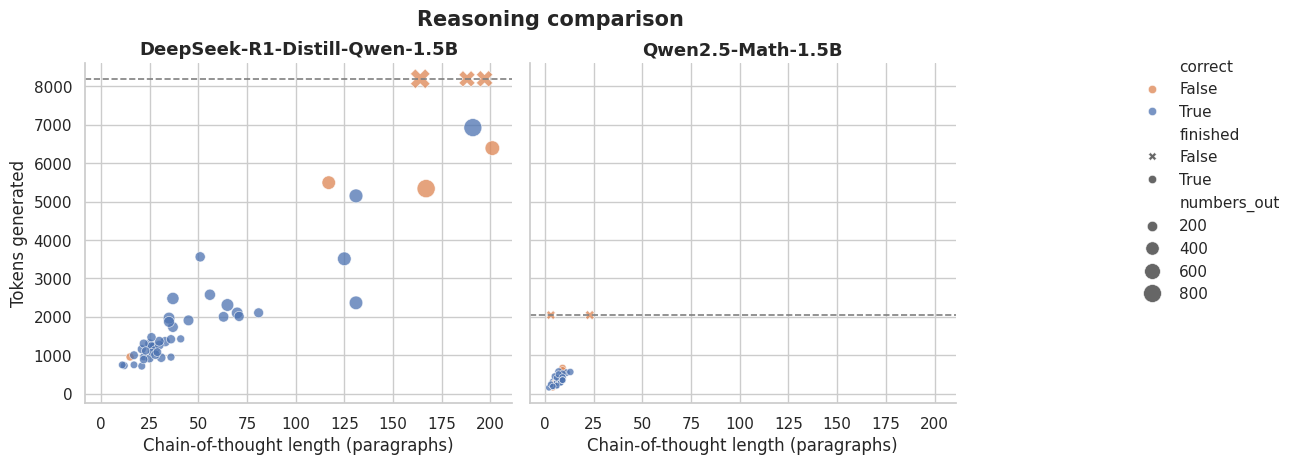

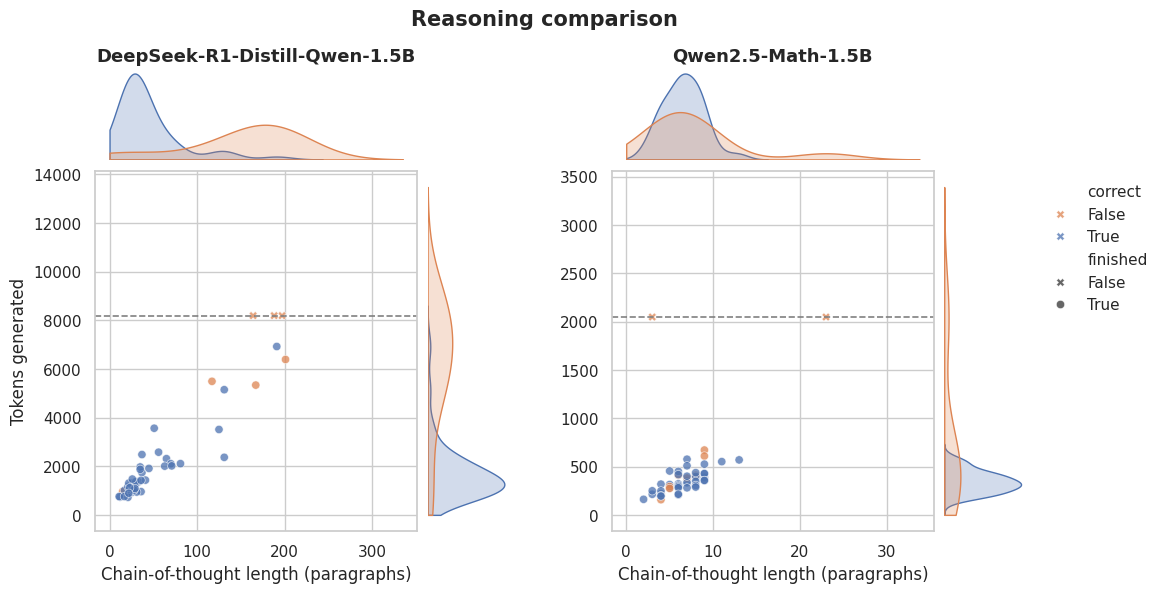

In [89]:
# Relplot
g = sns.relplot(
    data=combined_df, x="chain_of_thought_length", y="n_tokens", col="model_short",
    hue="correct", size="numbers_out", style="finished",
    palette=palette, sizes=(20, 200),
    markers={True: "o", False: "X"}, alpha=0.75, edgecolor="white", linewidth=0.5,
    height=4.5, aspect=1.1,
)

lines = {
    "DeepSeek-R1-Distill-Qwen-1.5B": int(df_grouped[df_grouped["model_short"] == "DeepSeek-R1-Distill-Qwen-1.5B"]["max_tokens"].iloc[0]),
    "Qwen2.5-Math-1.5B": int(df_grouped[df_grouped["model_short"] == "Qwen2.5-Math-1.5B"]["max_tokens"].iloc[0])
    }

for model, ax in g.axes_dict.items():
    ax.axhline(lines[model], color="gray", linestyle="--", linewidth=1.2)
    
g.set_titles("{col_name}", size=13, weight="bold")
g.set_axis_labels("Chain-of-thought length (paragraphs)", "Tokens generated")
g.figure.suptitle("Reasoning comparison", y=1.03, size=15, weight="bold")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 0.95), frameon=False)
plt.show()

# JointGrid for each model
models = combined_df["model_short"].unique()
x, y = "chain_of_thought_length", "n_tokens"

fig = plt.figure(figsize=(6 * len(models), 6))
outer = fig.add_gridspec(1, len(models), wspace=0.25)

for k, model in enumerate(models):
    d = combined_df[combined_df["model_short"] == model]
    inner = outer[k].subgridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4), hspace=0.05, wspace=0.05)
    ax       = fig.add_subplot(inner[1, 0])
    ax_top   = fig.add_subplot(inner[0, 0], sharex=ax)
    ax_right = fig.add_subplot(inner[1, 1], sharey=ax)

    sns.scatterplot(data=d, x=x, y=y, hue="correct", style="finished", markers={True: "o", False: "X"},
                    palette=palette, alpha=0.75, edgecolor="white", ax=ax, legend=(k == len(models) - 1))
    sns.kdeplot(data=d, x=x, hue="correct", palette=palette, fill=True, common_norm=False,
                clip=(0, None), warn_singular=False, legend=False, ax=ax_top)
    sns.kdeplot(data=d, y=y, hue="correct", palette=palette, fill=True, common_norm=False,
                clip=(0, None), warn_singular=False, legend=False, ax=ax_right)

    ax.axhline(lines[model], color="gray", linestyle="--", linewidth=1.2)
    ax.set(xlabel="Chain-of-thought length (paragraphs)", ylabel="Tokens generated" if k == 0 else "")
    ax_top.set_title(model, size=13, weight="bold")
    ax_top.axis("off")
    ax_right.axis("off")

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.3, 1), frameon=False)
fig.suptitle("Reasoning comparison", size=15, weight="bold")
plt.show()


Interpretation:
 - Most of the NOK results comes from a hitting the token limit!
 - The reasoning model (DeepSeek R1) used more tokens and built a longer chain of tought to get an ansewer, but it also brought a higher number of correct answers

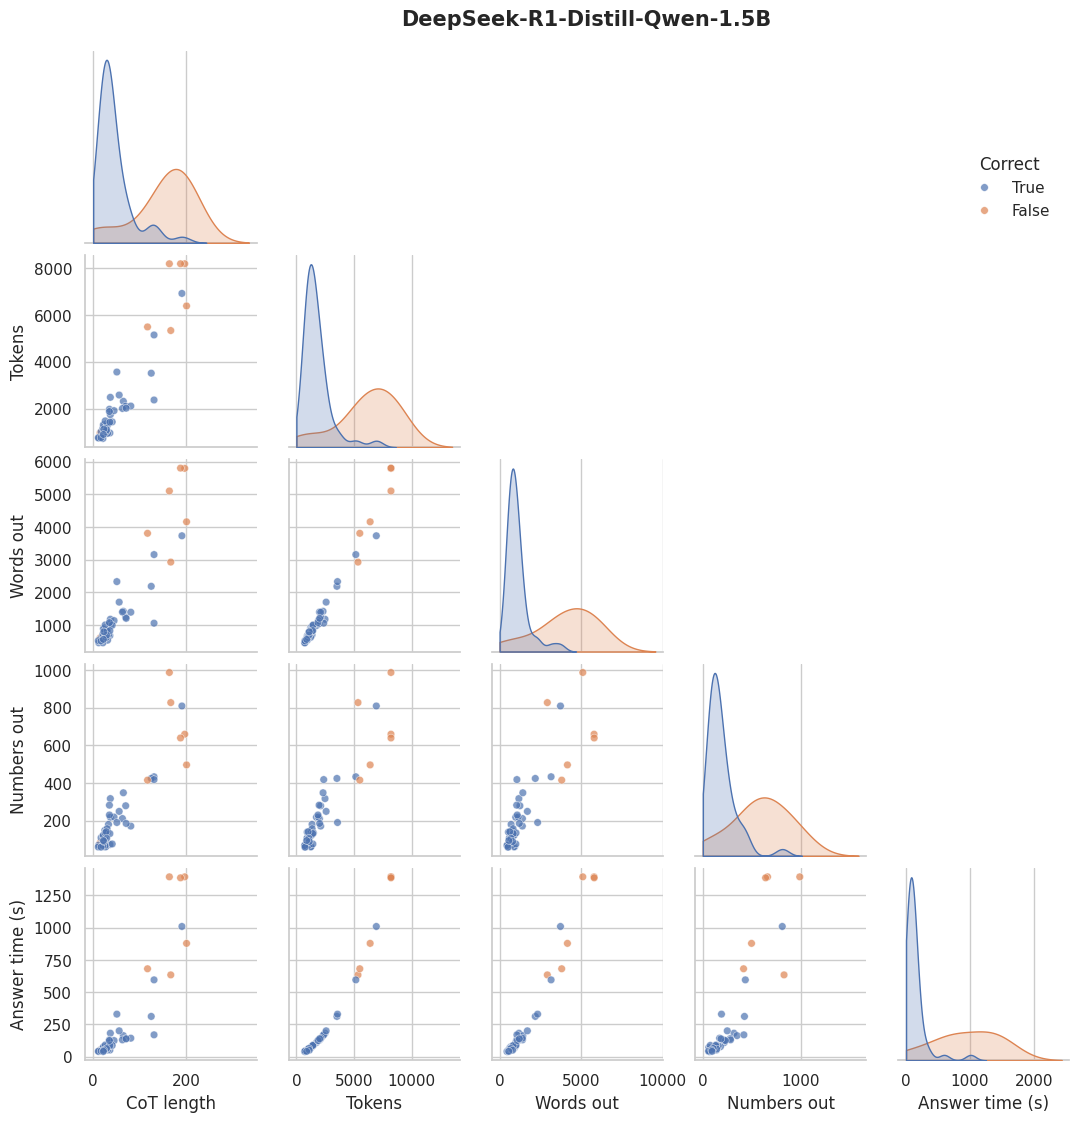

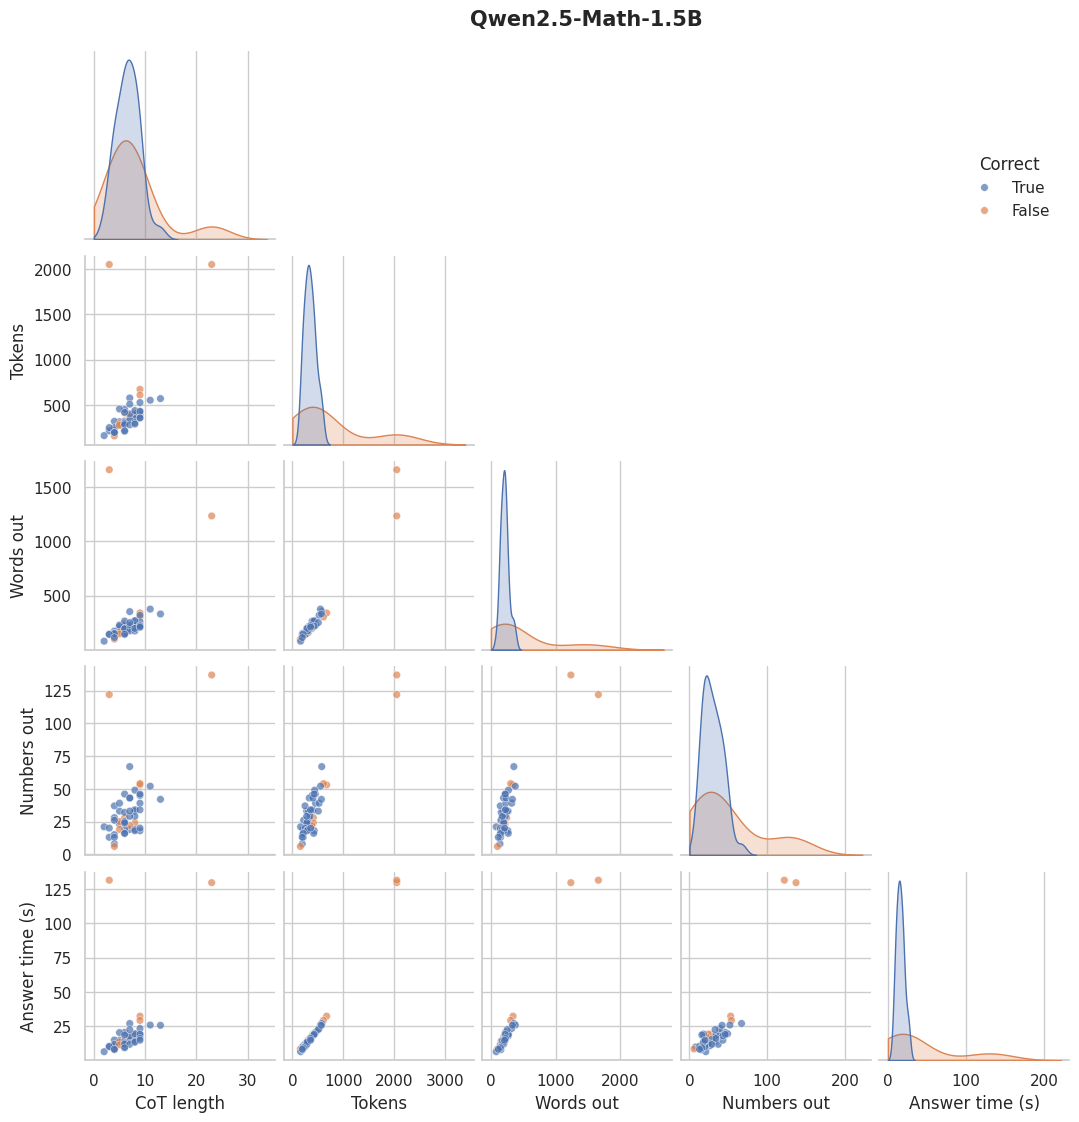

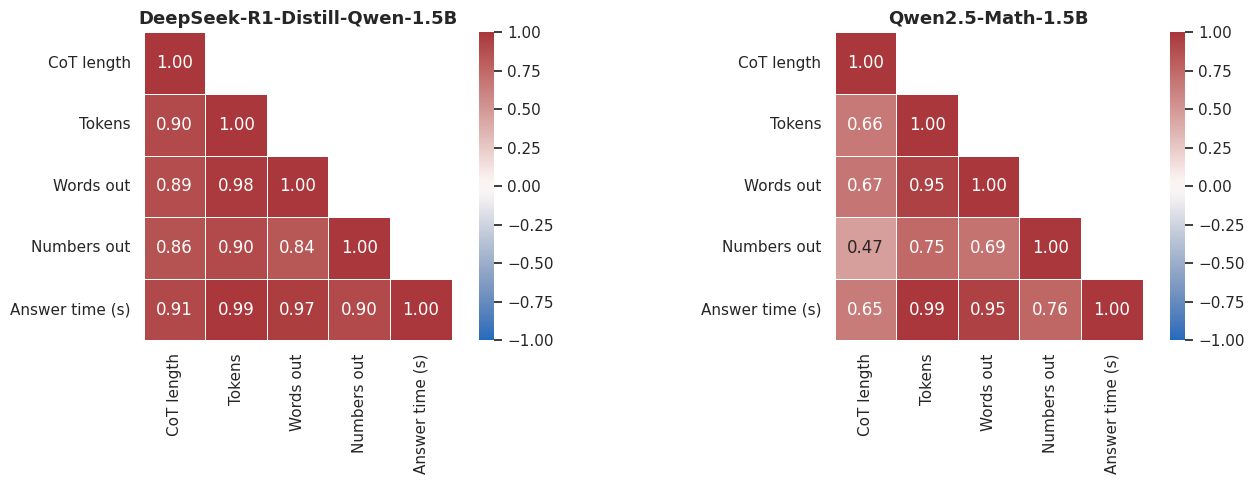

In [ ]:
# Pairplot
cols = {"chain_of_thought_length": "CoT length", "n_tokens": "Tokens",
        "words_out": "Words out", "numbers_out": "Numbers out", "answer_time": "Answer time (s)"}

for model in combined_df["model_short"].unique():
    d = combined_df[combined_df["model_short"] == model].rename(columns=cols)

    g = sns.pairplot(d, vars=list(cols.values()), hue="correct", palette=palette, hue_order=[True, False],
                     corner=True, height=2.2, diag_kind="kde",
                     plot_kws={"alpha": 0.7, "s": 30, "edgecolor": "white", "linewidth": 0.4},
                     diag_kws={"fill": True, "common_norm": False, "clip": (0, None), "warn_singular": False})
    g.figure.suptitle(model, size=15, weight="bold", y=1.02)
    sns.move_legend(g, "upper right", bbox_to_anchor=(0.9, 0.9), title="Correct", frameon=False)
    plt.show()

# Correlation heatmaps
models = combined_df["model_short"].unique()
fig, axes = plt.subplots(1, len(models), figsize=(14, 5))

for ax, model in zip(axes, models):
    model_df = combined_df[combined_df["model_short"] == model]
    corr = model_df[list(cols)].corr(method="spearman").rename(columns=cols, index=cols)
    matrix = np.triu(corr) - np.eye(corr.shape[0], dtype=bool)

    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax, mask=matrix, square=True, linewidths=0.5)
    ax.set_title(model, size=13, weight="bold")
    ax.grid(False)

plt.tight_layout()
plt.show()
